In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q kagglehub

from google.colab import userdata
import os

os.environ["KAGGLE_API_KEY"] = userdata.get("KAGGLE_API_KEY")

In [ ]:
import kagglehub

path = kagglehub.dataset_download(
    "dataclusterlabs/indian-vehicle-dataset",
    output_dir="/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles"
)

print(path)

In [ ]:
import os
import shutil
import random
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter
import yaml

# ==========================================
# 1. PATHS
# ==========================================

DATASET_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/auto/auto"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/auto"
)

random.seed(42)

# ==========================================
# 2. FIND XML FILES AND MATCH IMAGES
# ==========================================

image_extensions = [".jpg", ".jpeg", ".png"]

annotations = []

for xml_file in DATASET_DIR.rglob("*.xml"):

    try:
        root = ET.parse(xml_file).getroot()

        filename = root.findtext("filename")

        image_path = None

        # First try the filename specified in XML
        if filename:
            candidate = xml_file.parent / Path(filename).name

            if candidate.exists():
                image_path = candidate

        # Fallback: find image with matching stem
        if image_path is None:
            for ext in image_extensions:
                candidate = xml_file.with_suffix(ext)

                if candidate.exists():
                    image_path = candidate
                    break

        if image_path is not None:
            annotations.append((image_path, xml_file))

    except Exception as e:
        print("Invalid XML:", xml_file, e)

print("Matched image-annotation pairs:", len(annotations))

# ==========================================
# 3. EXTRACT ALL CLASS NAMES
# ==========================================

all_classes = set()

for image_path, xml_file in annotations:

    root = ET.parse(xml_file).getroot()

    for obj in root.findall("object"):

        class_name = obj.findtext("name")

        if class_name:
            all_classes.add(class_name.strip())

classes = sorted(all_classes)

class_to_id = {
    name: i for i, name in enumerate(classes)
}

print("\nClasses found:")

for name, class_id in class_to_id.items():
    print(class_id, ":", name)

# ==========================================
# 4. CREATE YOLO FOLDER STRUCTURE
# ==========================================

for split in ["train", "val", "test"]:

    (OUTPUT_DIR / "images" / split).mkdir(
        parents=True, exist_ok=True
    )

    (OUTPUT_DIR / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

# ==========================================
# 5. SPLIT DATASET
# ==========================================

random.shuffle(annotations)

total = len(annotations)

train_end = int(total * 0.8)
val_end = int(total * 0.9)

splits = {
    "train": annotations[:train_end],
    "val": annotations[train_end:val_end],
    "test": annotations[val_end:]
}

# ==========================================
# 6. CONVERT VOC XML TO YOLO TXT
# ==========================================

image_counts = Counter()
instance_counts = Counter()

from PIL import Image

for split, files in splits.items():

    for image_path, xml_file in files:

        root = ET.parse(xml_file).getroot()

        # Unique filename to avoid collisions
        unique_name = (
            str(image_path.relative_to(DATASET_DIR))
            .replace("\\", "_")
            .replace("/", "_")
        )

        image_name = Path(unique_name).name

        # Copy image
        destination_image = (
            OUTPUT_DIR / "images" / split / image_name
        )

        shutil.copy2(image_path, destination_image)

        # Get actual image dimensions
        with Image.open(image_path) as img:
            img_width, img_height = img.size

        yolo_annotations = []
        image_classes = set()

        for obj in root.findall("object"):

            class_name = obj.findtext("name")

            if not class_name:
                continue

            class_name = class_name.strip()

            bbox = obj.find("bndbox")

            if bbox is None:
                continue

            xmin = float(bbox.findtext("xmin"))
            ymin = float(bbox.findtext("ymin"))
            xmax = float(bbox.findtext("xmax"))
            ymax = float(bbox.findtext("ymax"))

            # Validate bounding box
            if not (
                0 <= xmin < xmax <= img_width
                and 0 <= ymin < ymax <= img_height
            ):
                continue

            # Pascal VOC -> YOLO
            x_center = ((xmin + xmax) / 2) / img_width
            y_center = ((ymin + ymax) / 2) / img_height

            width = (xmax - xmin) / img_width
            height = (ymax - ymin) / img_height

            class_id = class_to_id[class_name]

            yolo_annotations.append(
                f"{class_id} {x_center:.6f} {y_center:.6f} "
                f"{width:.6f} {height:.6f}"
            )

            instance_counts[class_name] += 1
            image_classes.add(class_name)

        # Save YOLO TXT
        label_name = Path(image_name).with_suffix(".txt")

        label_path = (
            OUTPUT_DIR / "labels" / split / label_name
        )

        with open(label_path, "w") as f:
            f.write("\n".join(yolo_annotations))

        for class_name in image_classes:
            image_counts[class_name] += 1

    print(f"{split}: {len(files)} images processed")

# ==========================================
# 7. GENERATE data.yaml
# ==========================================

data_config = {
    "path": str(OUTPUT_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(classes),
    "names": classes
}

with open(OUTPUT_DIR / "data.yaml", "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

# ==========================================
# 8. DISPLAY STATISTICS
# ==========================================

print("\n========== CONVERSION COMPLETE ==========")

print("Total images:", total)
print("Training images:", len(splits["train"]))
print("Validation images:", len(splits["val"]))
print("Testing images:", len(splits["test"]))

print("\nClass statistics:")

for class_name in classes:
    print(
        f"{class_name}: "
        f"{instance_counts[class_name]} instances, "
        f"{image_counts[class_name]} images"
    )

print("\nYOLO dataset saved at:", OUTPUT_DIR)

Matched image-annotation pairs: 0

Classes found:
train: 0 images processed
val: 0 images processed
test: 0 images processed

========== CONVERSION COMPLETE ==========
Total images: 0
Training images: 0
Validation images: 0
Testing images: 0

Class statistics:

YOLO dataset saved at: /content/drive/MyDrive/Hazard_Detection/raw_datasets/auto


In [ ]:
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/auto"
)

for item in BASE_DIR.iterdir():
    print(item.name, "->", "Directory" if item.is_dir() else "File")

print("\nXML FILES:")
for f in list(BASE_DIR.rglob("*.xml"))[:10]:
    print(f)

print("\nIMAGE FILES:")
for f in list(BASE_DIR.rglob("*.jpg"))[:10]:
    print(f)

Annotations -> Directory
auto -> Directory
.complete -> Directory
data.yaml -> File
images -> Directory
labels -> Directory

XML FILES:
/content/drive/MyDrive/Hazard_Detection/raw_datasets/auto/Annotations/Annotations/Datacluster Labs Auto (14).xml
/content/drive/MyDrive/Hazard_Detection/raw_datasets/auto/Annotations/Annotations/Datacluster Labs Auto (10).xml
/content/drive/MyDrive/Hazard_Detection/raw_datasets/auto/Annotations/Annotations/Datacluster Labs Auto (13).xml
/content/drive/MyDrive/Hazard_Detection/raw_datasets/auto/Annotations/Annotations/Datacluster Labs Auto (19).xml
/content/drive/MyDrive/Hazard_Detection/raw_datasets/auto/Annotations/Annotations/Datacluster Labs Auto (20).xml
/content/drive/MyDrive/Hazard_Detection/raw_datasets/auto/Annotations/Annotations/Datacluster Labs Auto (15).xml
/content/drive/MyDrive/Hazard_Detection/raw_datasets/auto/Annotations/Annotations/Datacluster Labs Auto (12).xml
/content/drive/MyDrive/Hazard_Detection/raw_datasets/auto/Annotations/Ann

In [ ]:
from pathlib import Path
import xml.etree.ElementTree as ET
from collections import Counter

BASE_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/auto"
)

IMAGE_DIR = BASE_DIR / "auto" / "auto"
ANNOTATION_DIR = BASE_DIR / "Annotations" / "Annotations"

classes = Counter()
matched = 0
unmatched = []

for xml_file in ANNOTATION_DIR.glob("*.xml"):

    image_path = IMAGE_DIR / (xml_file.stem + ".jpg")

    if not image_path.exists():
        unmatched.append(xml_file.name)
        continue

    matched += 1

    root = ET.parse(xml_file).getroot()

    for obj in root.findall("object"):
        name = obj.findtext("name")
        if name:
            classes[name.strip()] += 1

print("Matched pairs:", matched)
print("Unmatched XML files:", len(unmatched))

print("\nOriginal classes and annotation counts:")
for name, count in classes.items():
    print(f"{name}: {count}")

print("\nExisting output folders:")
for folder in ["images", "labels"]:
    path = BASE_DIR / folder
    print(folder, "exists:", path.exists())
    if path.exists():
        print("Files:", len(list(path.rglob("*"))))

Matched pairs: 100
Unmatched XML files: 0

Original classes and annotation counts:
autorickshaw: 118

Existing output folders:
images exists: True
Files: 3
labels exists: True
Files: 3


In [ ]:

import shutil
import random
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter
from PIL import Image
import yaml

# ==========================================
# 1. PATHS
# ==========================================

BASE_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/auto"
)

IMAGE_DIR = BASE_DIR / "auto" / "auto"
ANNOTATION_DIR = BASE_DIR / "Annotations" / "Annotations"
OUTPUT_DIR = BASE_DIR / "YOLO"

random.seed(42)

if OUTPUT_DIR.exists():
    raise FileExistsError(
        f"{OUTPUT_DIR} already exists. Inspect it before proceeding."
    )

# ==========================================
# 2. MASTER CLASSES
# ==========================================

MASTER_CLASSES = [
    "person",
    "two_wheeler",
    "car",
    "auto_rickshaw",
    "large_vehicle",
    "large_animal",
    "dog",
    "pothole",
    "open_drain",
    "speed_breaker",
    "stairs_up",
    "stairs_down",
    "curb_or_step",
    "obstacle",
    "vendor_stall",
    "bench",
    "chair",
    "door",
    "sports_balls",
    "traffic_lights",
    "other_hazards"
]

# Original class -> master ID
CLASS_MAPPING = {
    "autorickshaw": 3
}

# ==========================================
# 3. MATCH XML AND IMAGES
# ==========================================

annotations = []

for xml_file in ANNOTATION_DIR.rglob("*.xml"):

    root = ET.parse(xml_file).getroot()

    filename = root.findtext("filename")

    candidates = []

    if filename:
        candidates.append(IMAGE_DIR / Path(filename).name)

    candidates.append(IMAGE_DIR / (xml_file.stem + ".jpg"))

    image_path = next(
        (p for p in candidates if p.exists()),
        None
    )

    if image_path is None:
        raise FileNotFoundError(
            f"No matching image for {xml_file.name}"
        )

    annotations.append((image_path, xml_file))

print("Matched pairs:", len(annotations))

# ==========================================
# 4. CREATE OUTPUT FOLDERS
# ==========================================

for split in ["train", "val", "test"]:
    (OUTPUT_DIR / "images" / split).mkdir(
        parents=True, exist_ok=True
    )
    (OUTPUT_DIR / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

# ==========================================
# 5. SPLIT DATASET
# ==========================================

random.shuffle(annotations)

total = len(annotations)

train_end = int(total * 0.8)
val_end = int(total * 0.9)

splits = {
    "train": annotations[:train_end],
    "val": annotations[train_end:val_end],
    "test": annotations[val_end:]
}

# ==========================================
# 6. VOC XML -> YOLO
# ==========================================

instance_counts = Counter()
image_counts = Counter()
invalid_boxes = 0

for split, files in splits.items():

    for image_path, xml_file in files:

        root = ET.parse(xml_file).getroot()

        with Image.open(image_path) as img:
            img_width, img_height = img.size

        yolo_lines = []
        image_classes = set()

        for obj in root.findall("object"):

            class_name = obj.findtext("name")

            if not class_name:
                continue

            class_name = class_name.strip().lower()

            if class_name not in CLASS_MAPPING:
                raise ValueError(
                    f"Unknown class: {class_name}"
                )

            bbox = obj.find("bndbox")

            if bbox is None:
                continue

            xmin = float(bbox.findtext("xmin"))
            ymin = float(bbox.findtext("ymin"))
            xmax = float(bbox.findtext("xmax"))
            ymax = float(bbox.findtext("ymax"))

            # Clip coordinates to image boundaries
            xmin = max(0, min(xmin, img_width))
            xmax = max(0, min(xmax, img_width))
            ymin = max(0, min(ymin, img_height))
            ymax = max(0, min(ymax, img_height))

            if xmin >= xmax or ymin >= ymax:
                invalid_boxes += 1
                continue

            x_center = ((xmin + xmax) / 2) / img_width
            y_center = ((ymin + ymax) / 2) / img_height

            width = (xmax - xmin) / img_width
            height = (ymax - ymin) / img_height

            class_id = CLASS_MAPPING[class_name]

            yolo_lines.append(
                f"{class_id} {x_center:.6f} "
                f"{y_center:.6f} {width:.6f} {height:.6f}"
            )

            instance_counts[class_name] += 1
            image_classes.add(class_name)

        # Keep original image filename
        shutil.copy2(
            image_path,
            OUTPUT_DIR / "images" / split / image_path.name
        )

        label_path = (
            OUTPUT_DIR / "labels" / split /
            f"{image_path.stem}.txt"
        )

        with open(label_path, "w") as f:
            f.write("\n".join(yolo_lines))

        for name in image_classes:
            image_counts[name] += 1

    print(f"{split}: {len(files)} images processed")

# ==========================================
# 7. CREATE data.yaml
# ==========================================

data_config = {
    "path": str(OUTPUT_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(MASTER_CLASSES),
    "names": MASTER_CLASSES
}

with open(OUTPUT_DIR / "data.yaml", "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

# ==========================================
# 8. STATISTICS
# ==========================================

print("\n========== CONVERSION COMPLETE ==========")

for split in splits:
    print(
        split,
        "images:",
        len(list((OUTPUT_DIR / "images" / split).glob("*")))
    )

print("\nClass statistics:")

for name, class_id in CLASS_MAPPING.items():
    print(
        f"{name} -> {MASTER_CLASSES[class_id]}: "
        f"{instance_counts[name]} instances, "
        f"{image_counts[name]} images"
    )

print("Invalid boxes:", invalid_boxes)
print("Output:", OUTPUT_DIR)


Matched pairs: 100
train: 80 images processed
val: 10 images processed
test: 10 images processed

========== CONVERSION COMPLETE ==========
train images: 80
val images: 10
test images: 10

Class statistics:
autorickshaw -> auto_rickshaw: 118 instances, 100 images
Invalid boxes: 0
Output: /content/drive/MyDrive/Hazard_Detection/raw_datasets/auto/YOLO


Total annotations: 118
Total classes: 1


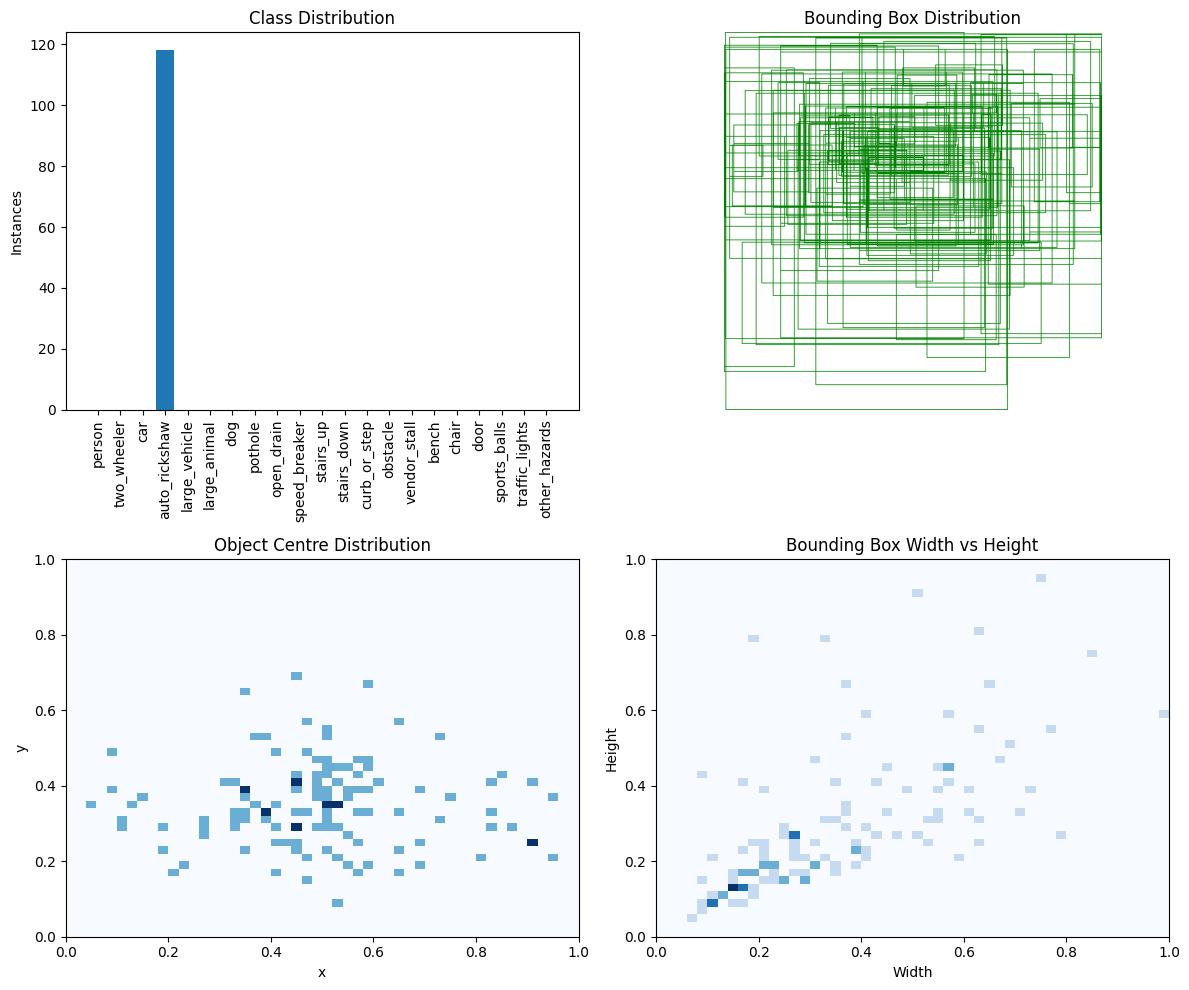

Saved analysis to: /content/drive/MyDrive/Hazard_Detection/raw_datasets/auto/YOLO/dataset_analysis.jpg


In [ ]:
import os
import yaml
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import ImageDraw, Image

# Dataset location
DATASET_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/auto/YOLO"
)

# Read data.yaml
yaml_path = DATASET_DIR / "data.yaml"

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

names = config["names"]

if isinstance(names, list):
    names = dict(enumerate(names))

# Find label directories using the dataset splits
base = Path(config.get("path", DATASET_DIR))

if not base.is_absolute():
    base = (yaml_path.parent / base).resolve()

label_dirs = set()

for split in ["train", "val", "valid", "test"]:
    split_path = config.get(split)

    if not split_path:
        continue

    paths = split_path if isinstance(split_path, list) else [split_path]

    for p in paths:
        p = Path(p)

        if not p.is_absolute():
            p = (base / p).resolve()

        parts = list(p.parts)

        if "images" in parts:
            parts[parts.index("images")] = "labels"
            label_dirs.add(Path(*parts))
        else:
            print("Check label folder for:", p)

# Read annotations
classes = []
boxes = []

for label_dir in label_dirs:
    if not label_dir.exists():
        print("Missing:", label_dir)
        continue

    for file in label_dir.rglob("*.txt"):
        with open(file, "r") as f:
            for line in f:
                values = line.strip().split()

                if len(values) < 5:
                    continue

                cls, x, y, w, h = map(float, values[:5])

                classes.append(int(cls))
                boxes.append([x, y, w, h])

classes = np.array(classes)
boxes = np.array(boxes)

print("Total annotations:", len(classes))
print("Total classes:", len(set(classes)))

# Class distribution
counts = np.bincount(
    classes.astype(int),
    minlength=len(names)
)

# Generate plots
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

# 1. Class distribution
ax[0, 0].bar(range(len(names)), counts)

ax[0, 0].set_xticks(range(len(names)))
ax[0, 0].set_xticklabels(
    [names[i] for i in range(len(names))],
    rotation=90
)

ax[0, 0].set_ylabel("Instances")
ax[0, 0].set_title("Class Distribution")

# 2. Bounding box visualization
img = Image.new("RGB", (1000, 1000), "white")
draw = ImageDraw.Draw(img)

for x, y, w, h in boxes[:500]:
    x1 = (x - w/2) * 1000
    y1 = (y - h/2) * 1000
    x2 = (x + w/2) * 1000
    y2 = (y + h/2) * 1000

    draw.rectangle([x1, y1, x2, y2], outline="green", width=2)

ax[0, 1].imshow(img)
ax[0, 1].set_title("Bounding Box Distribution")
ax[0, 1].axis("off")

# 3. Object centre distribution
ax[1, 0].hist2d(
    boxes[:, 0],
    boxes[:, 1],
    bins=50,
    range=[[0, 1], [0, 1]],
    cmap="Blues"
)

ax[1, 0].set_xlabel("x")
ax[1, 0].set_ylabel("y")
ax[1, 0].set_title("Object Centre Distribution")

# 4. Width-height distribution
ax[1, 1].hist2d(
    boxes[:, 2],
    boxes[:, 3],
    bins=50,
    range=[[0, 1], [0, 1]],
    cmap="Blues"
)

ax[1, 1].set_xlabel("Width")
ax[1, 1].set_ylabel("Height")
ax[1, 1].set_title("Bounding Box Width vs Height")

plt.tight_layout()

# Save results
output_path = DATASET_DIR / "dataset_analysis.jpg"

plt.savefig(output_path, dpi=200)
plt.show()

print("Saved analysis to:", output_path)

In [2]:

# ============================================================
# DOWNLOAD VIT AUTO-RICKSHAW DATASET - VERSION 9
# ============================================================

!pip install -q roboflow pyyaml

from google.colab import userdata
from roboflow import Roboflow

from pathlib import Path
from collections import Counter
import yaml


# ------------------------------------------------------------
# 1. CONNECT TO ROBOFLOW
# ------------------------------------------------------------

API_KEY = userdata.get("ROBFLOW_KEY")

if not API_KEY:
    raise ValueError(
        "ROBFLOW_KEY was not found in Colab Secrets."
    )

rf = Roboflow(api_key=API_KEY)


# ------------------------------------------------------------
# 2. SELECT PROJECT AND VERSION
# ------------------------------------------------------------

project = rf.workspace("vit-0mr4g").project(
    "auto-rickshaw-oobkc"
)

version = project.version(9)


# ------------------------------------------------------------
# 3. DOWNLOAD LOCATION
# ------------------------------------------------------------

DOWNLOAD_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/"
    "raw_datasets/auto_rickshaw_vit_v9"
)

if DOWNLOAD_DIR.exists():
    raise FileExistsError(
        f"Destination already exists: {DOWNLOAD_DIR}\n"
        "Please inspect it before downloading again."
    )

DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 4. DOWNLOAD IN YOLO FORMAT
# ------------------------------------------------------------

dataset = version.download(
    "yolov8",
    location=str(DOWNLOAD_DIR)
)

print("\nDOWNLOAD COMPLETED!")
print("Dataset location:", DOWNLOAD_DIR)


# ------------------------------------------------------------
# 5. LOCATE AND READ DATA YAML
# ------------------------------------------------------------

yaml_files = list(DOWNLOAD_DIR.rglob("data.yaml"))

if not yaml_files:
    raise FileNotFoundError(
        "Could not find data.yaml after download."
    )

DATA_YAML = yaml_files[0]

with open(DATA_YAML, "r") as f:
    data = yaml.safe_load(f)

print("\n" + "=" * 60)
print("DOWNLOADED DATASET CONFIGURATION")
print("=" * 60)

print("YAML:", DATA_YAML)
print("Number of classes:", data.get("nc"))
print("Class names:", data.get("names"))


# ------------------------------------------------------------
# 6. FIND SPLIT DIRECTORIES
# ------------------------------------------------------------

SPLITS = ["train", "valid", "val", "test"]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

def find_split_dirs(split):

    candidates = [
        (
            DOWNLOAD_DIR / split / "images",
            DOWNLOAD_DIR / split / "labels"
        ),
        (
            DOWNLOAD_DIR / "images" / split,
            DOWNLOAD_DIR / "labels" / split
        )
    ]

    for image_dir, label_dir in candidates:

        if image_dir.is_dir() and label_dir.is_dir():
            return image_dir, label_dir

    return None, None


# ------------------------------------------------------------
# 7. COUNT ACTUAL ANNOTATED INSTANCES
# ------------------------------------------------------------

names = data.get("names", {})

if isinstance(names, list):
    class_names = {
        i: str(name)
        for i, name in enumerate(names)
    }
else:
    class_names = {
        int(i): str(name)
        for i, name in names.items()
    }

print("\n" + "=" * 60)
print("ACTUAL ANNOTATION COUNTS")
print("=" * 60)

total_images = 0
total_instances = Counter()

for split in SPLITS:

    image_dir, label_dir = find_split_dirs(split)

    if image_dir is None:
        continue

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    labels = list(label_dir.glob("*.txt"))

    split_counts = Counter()
    malformed = 0

    for label_file in labels:

        with open(label_file, "r") as f:

            for line in f:

                parts = line.strip().split()

                if not parts:
                    continue

                if len(parts) != 5:
                    malformed += 1
                    continue

                try:
                    class_id = int(parts[0])
                except ValueError:
                    malformed += 1
                    continue

                split_counts[class_id] += 1
                total_instances[class_id] += 1

    total_images += len(images)

    print(f"\n{split.upper()}")
    print("-" * 40)
    print("Images:", len(images))
    print("Label files:", len(labels))
    print("Total instances:", sum(split_counts.values()))
    print("Malformed lines:", malformed)

    for class_id, count in sorted(split_counts.items()):
        print(
            f"Class {class_id} "
            f"({class_names.get(class_id, 'UNKNOWN')}): "
            f"{count} instances"
        )


# ------------------------------------------------------------
# 8. OVERALL COUNTS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("OVERALL DATASET COUNTS")
print("=" * 60)

print("Total images:", total_images)
print("Total instances:", sum(total_instances.values()))

for class_id, count in sorted(total_instances.items()):
    print(
        f"{class_id} - "
        f"{class_names.get(class_id, 'UNKNOWN')}: "
        f"{count} instances"
    )

print("\nDownload and initial audit complete.")


loading Roboflow workspace...
loading Roboflow project...

DOWNLOAD COMPLETED!
Dataset location: /content/drive/MyDrive/Hazard_Detection/raw_datasets/auto_rickshaw_vit_v9


FileNotFoundError: Could not find data.yaml after download.

In [3]:

from pathlib import Path

DOWNLOAD_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/"
    "raw_datasets/auto_rickshaw_vit_v9"
)

print("=" * 65)
print("ROBOFLOW DOWNLOAD FOLDER INSPECTION")
print("=" * 65)

print("Folder exists:", DOWNLOAD_DIR.exists())
print("Folder:", DOWNLOAD_DIR)

if DOWNLOAD_DIR.exists():

    all_files = list(DOWNLOAD_DIR.rglob("*"))

    print("\nTotal files and folders:", len(all_files))

    print("\nFolder structure (first 100 entries):")

    for path in all_files[:100]:

        relative = path.relative_to(DOWNLOAD_DIR)

        if path.is_dir():
            print("[DIR] ", relative)
        else:
            print("[FILE]", relative)

    print("\nYAML files found:")

    yaml_files = list(DOWNLOAD_DIR.rglob("*.yaml")) + \
                 list(DOWNLOAD_DIR.rglob("*.yml"))

    if yaml_files:
        for path in yaml_files:
            print(path)
    else:
        print("No YAML files found.")

    print("\nImage counts by folder:")

    extensions = {".jpg", ".jpeg", ".png", ".webp"}

    for folder in DOWNLOAD_DIR.rglob("*"):

        if folder.is_dir():

            images = [
                p for p in folder.iterdir()
                if p.is_file() and p.suffix.lower() in extensions
            ]

            if images:
                print(folder.relative_to(DOWNLOAD_DIR), ":", len(images))


ROBOFLOW DOWNLOAD FOLDER INSPECTION
Folder exists: True
Folder: /content/drive/MyDrive/Hazard_Detection/raw_datasets/auto_rickshaw_vit_v9

Total files and folders: 0

Folder structure (first 100 entries):

YAML files found:
No YAML files found.

Image counts by folder:


In [4]:

import os
from pathlib import Path

print("=" * 65)
print("ROBOFLOW DOWNLOAD LOCATION DIAGNOSTIC")
print("=" * 65)

print("\nCurrent working directory:")
print(os.getcwd())

print("\nRoboflow dataset object:")

try:
    print("Dataset location:", dataset.location)
except Exception as e:
    print("Location unavailable:", e)

try:
    print("Dataset name:", dataset.name)
except Exception as e:
    print("Name unavailable:", e)

print("\nSearching /content for downloaded YAML files...")

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive/Hazard_Detection/raw_datasets")
]

for root in search_roots:

    print(f"\nSEARCH ROOT: {root}")

    if not root.exists():
        print("Root does not exist.")
        continue

    found = 0

    for yaml_file in root.rglob("data.yaml"):

        print("FOUND:", yaml_file)
        found += 1

        if found >= 20:
            print("Search limit reached.")
            break

    if found == 0:
        print("No data.yaml found.")

print("\nDiagnostic complete.")


ROBOFLOW DOWNLOAD LOCATION DIAGNOSTIC

Current working directory:
/content

Roboflow dataset object:
Dataset location: /content/drive/MyDrive/Hazard_Detection/raw_datasets/auto_rickshaw_vit_v9
Dataset name: Auto rickshaw

Searching /content for downloaded YAML files...

SEARCH ROOT: /content
FOUND: /content/drive/MyDrive/Hazard_Detection/raw_datasets/coco_dataset/data.yaml
FOUND: /content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles/data.yaml
FOUND: /content/drive/MyDrive/Hazard_Detection/raw_datasets/speed_breaker/data.yaml
FOUND: /content/drive/MyDrive/Hazard_Detection/raw_datasets/curb_or_step/data.yaml
FOUND: /content/drive/MyDrive/Hazard_Detection/raw_datasets/doors/final_dataset/data.yaml
FOUND: /content/drive/MyDrive/Hazard_Detection/raw_datasets/obstacle/source_datasets/bollards/data.yaml
FOUND: /content/drive/MyDrive/Hazard_Detection/raw_datasets/obstacle/source_datasets/barricades/data.yaml
FOUND: /content/drive/MyDrive/Hazard_Detection/raw_datasets/obstacle/so

In [5]:

from google.colab import userdata
from roboflow import Roboflow

from pathlib import Path
import shutil
import os

# ==================================================
# 1. CONNECT TO ROBOFLOW
# ==================================================

API_KEY = userdata.get("ROBFLOW_KEY")

if not API_KEY:
    raise ValueError("ROBFLOW_KEY is missing.")

rf = Roboflow(api_key=API_KEY)

project = rf.workspace("vit-0mr4g").project(
    "auto-rickshaw-oobkc"
)

version = project.version(9)


# ==================================================
# 2. DOWNLOAD LOCALLY FIRST
# ==================================================

LOCAL_DOWNLOAD = Path("/content/vit_auto_rickshaw_v9")

if LOCAL_DOWNLOAD.exists():
    raise FileExistsError(
        f"{LOCAL_DOWNLOAD} already exists. "
        "Inspect it before downloading again."
    )

print("Starting Roboflow download...")

dataset = version.download(
    "yolov8"
)

print("\nRoboflow download call completed.")

print("Returned location:", dataset.location)


# ==================================================
# 3. FIND ACTUAL DOWNLOAD LOCATION
# ==================================================

download_location = Path(dataset.location)

if not download_location.exists():
    raise FileNotFoundError(
        f"Roboflow reported a location that does not exist: "
        f"{download_location}"
    )

yaml_files = list(download_location.rglob("data.yaml"))

if not yaml_files:
    raise FileNotFoundError(
        "Download location exists, but data.yaml is missing. "
        "We need to inspect the downloaded folder."
    )

print("\nYAML found:", yaml_files[0])

# Count images and labels
image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

images = [
    p for p in download_location.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

labels = list(download_location.rglob("*.txt"))

print("\nDOWNLOAD VERIFICATION")
print("=" * 50)
print("Images:", len(images))
print("Label files:", len(labels))

if len(images) == 0 or len(labels) == 0:
    raise RuntimeError(
        "Download appears incomplete. "
        "Not copying anything to Google Drive."
    )


# ==================================================
# 4. COPY VERIFIED DATASET TO GOOGLE DRIVE
# ==================================================

DRIVE_DESTINATION = Path(
    "/content/drive/MyDrive/Hazard_Detection/"
    "raw_datasets/auto_rickshaw_vit_v9"
)

if DRIVE_DESTINATION.exists():

    if any(DRIVE_DESTINATION.iterdir()):
        raise FileExistsError(
            "Google Drive destination is not empty. "
            "Stopping to protect existing files."
        )

    DRIVE_DESTINATION.rmdir()

shutil.copytree(
    download_location,
    DRIVE_DESTINATION
)


# ==================================================
# 5. VERIFY GOOGLE DRIVE COPY
# ==================================================

drive_images = [
    p for p in DRIVE_DESTINATION.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

drive_labels = list(DRIVE_DESTINATION.rglob("*.txt"))

drive_yaml = list(DRIVE_DESTINATION.rglob("data.yaml"))

print("\n" + "=" * 50)
print("GOOGLE DRIVE COPY VERIFICATION")
print("=" * 50)

print("Images copied:", len(drive_images))
print("Labels copied:", len(drive_labels))
print("YAML files:", len(drive_yaml))

if (
    len(drive_images) != len(images)
    or len(drive_labels) != len(labels)
    or not drive_yaml
):
    raise RuntimeError(
        "Drive copy verification failed. "
        "Do not proceed yet."
    )

print("\nSUCCESS!")
print("Dataset saved at:")
print(DRIVE_DESTINATION)


loading Roboflow workspace...
loading Roboflow project...
Starting Roboflow download...



Extracting Dataset Version Zip to Auto-rickshaw-9 in yolov8:: 100%|██████████| 9416/9416 [00:01<00:00, 6733.42it/s]



Roboflow download call completed.
Returned location: /content/Auto-rickshaw-9

YAML found: /content/Auto-rickshaw-9/data.yaml

DOWNLOAD VERIFICATION
Images: 4702
Label files: 4704

GOOGLE DRIVE COPY VERIFICATION
Images copied: 4702
Labels copied: 4704
YAML files: 1

SUCCESS!
Dataset saved at:
/content/drive/MyDrive/Hazard_Detection/raw_datasets/auto_rickshaw_vit_v9


In [6]:

from pathlib import Path
from collections import Counter
import yaml

ROOT = Path(
    "/content/drive/MyDrive/Hazard_Detection/"
    "raw_datasets/auto_rickshaw_vit_v9"
)

with open(ROOT / "data.yaml", "r") as f:
    config = yaml.safe_load(f)

print("DATASET CLASSES:")
print(config.get("names"))

print("\n" + "=" * 65)
print("AUTO-RICKSHAW ANNOTATION AUDIT")
print("=" * 65)

extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

for split in ["train", "valid", "val", "test"]:

    image_dir = ROOT / split / "images"
    label_dir = ROOT / split / "labels"

    if not image_dir.exists():
        image_dir = ROOT / "images" / split
        label_dir = ROOT / "labels" / split

    if not image_dir.exists() or not label_dir.exists():
        continue

    images = {
        p.stem for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in extensions
    }

    labels = {
        p.stem: p for p in label_dir.glob("*.txt")
    }

    counts = Counter()
    instances_per_image = Counter()
    malformed = 0
    invalid_boxes = 0

    for stem, label_path in labels.items():

        with open(label_path, "r") as f:
            lines = f.readlines()

        for line in lines:

            parts = line.strip().split()

            if not parts:
                continue

            if len(parts) != 5:
                malformed += 1
                continue

            try:
                class_id = int(parts[0])
                x, y, w, h = map(float, parts[1:])
            except ValueError:
                malformed += 1
                continue

            counts[class_id] += 1
            instances_per_image[stem] += 1

            if not (
                0 <= x <= 1 and
                0 <= y <= 1 and
                0 < w <= 1 and
                0 < h <= 1 and
                x - w/2 >= 0 and
                x + w/2 <= 1 and
                y - h/2 >= 0 and
                y + h/2 <= 1
            ):
                invalid_boxes += 1

    print(f"\n{split.upper()}")
    print("-" * 50)
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Matched pairs:", len(images & set(labels)))
    print("Images without labels:", len(images - set(labels)))
    print("Orphan labels:", len(set(labels) - images))

    print("\nInstances by class:")

    for class_id, count in sorted(counts.items()):
        print(f"Class {class_id}: {count} instances")

    print("\nTotal instances:", sum(counts.values()))
    print("Images with annotations:", len(instances_per_image))
    print("Malformed lines:", malformed)
    print("Invalid boxes:", invalid_boxes)

print("\nAUDIT COMPLETE")


DATASET CLASSES:
['Auto']

AUTO-RICKSHAW ANNOTATION AUDIT

TRAIN
--------------------------------------------------
Images: 4143
Labels: 4143
Matched pairs: 4143
Images without labels: 0
Orphan labels: 0

Instances by class:
Class 0: 6153 instances

Total instances: 6153
Images with annotations: 3939
Malformed lines: 3
Invalid boxes: 0

VALID
--------------------------------------------------
Images: 337
Labels: 337
Matched pairs: 337
Images without labels: 0
Orphan labels: 0

Instances by class:
Class 0: 541 instances

Total instances: 541
Images with annotations: 318
Malformed lines: 0
Invalid boxes: 0

TEST
--------------------------------------------------
Images: 222
Labels: 222
Matched pairs: 222
Images without labels: 0
Orphan labels: 0

Instances by class:
Class 0: 332 instances

Total instances: 332
Images with annotations: 214
Malformed lines: 0
Invalid boxes: 0

AUDIT COMPLETE


In [7]:
# ================================================================
# SELECT VIT AUTO-RICKSHAW DATASET
# Targets: 400 train, 100 valid, 100 test
# Source class 0 (Auto) -> Master class 3 (auto_rickshaw)
# ================================================================

from pathlib import Path
from collections import Counter
import hashlib
import random
import shutil
import csv
import yaml

# -----------------------------
# 1. PATHS AND SETTINGS
# -----------------------------

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Hazard_Detection"
)

SOURCE_ROOT = PROJECT_ROOT / "raw_datasets/auto_rickshaw_vit_v9"

# Existing dataset to check for duplicate images
EXISTING_AUTO_ROOT = PROJECT_ROOT / "raw_datasets/auto/YOLO"

# New output dataset
OUTPUT_ROOT = PROJECT_ROOT / "raw_datasets/auto_rickshaw_vit_selected"

MASTER_YAML = PROJECT_ROOT / "master_class/classes.yaml"

SOURCE_CLASS_ID = 0
MASTER_CLASS_ID = 3

TARGETS = {
    "train": 400,
    "valid": 100,
    "test": 100
}

SEED = 42

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"
}

random.seed(SEED)


# -----------------------------
# 2. BASIC CHECKS
# -----------------------------

assert SOURCE_ROOT.exists(), f"Source dataset not found: {SOURCE_ROOT}"
assert MASTER_YAML.exists(), f"Master YAML not found: {MASTER_YAML}"

if OUTPUT_ROOT.exists():
    raise FileExistsError(
        f"\nOutput folder already exists:\n{OUTPUT_ROOT}\n"
        "Rename or move it before running this script. "
        "The script will not overwrite an existing dataset."
    )

print("=" * 70)
print("VIT AUTO-RICKSHAW DATASET SELECTION")
print("=" * 70)


# -----------------------------
# 3. LOAD MASTER CLASSES
# -----------------------------

with open(MASTER_YAML, "r") as f:
    master_data = yaml.safe_load(f)

master_names = master_data["names"]

if isinstance(master_names, dict):
    master_names = [
        master_names[i] if i in master_names
        else master_names[str(i)]
        for i in range(len(master_names))
    ]

assert master_names[MASTER_CLASS_ID] == "auto_rickshaw", (
    f"Master class ID {MASTER_CLASS_ID} is "
    f"{master_names[MASTER_CLASS_ID]!r}, not 'auto_rickshaw'. "
    "Check your master YAML before continuing."
)

print(f"\nMaster classes loaded: {len(master_names)}")
print(f"Mapping: {SOURCE_CLASS_ID} (Auto) -> "
      f"{MASTER_CLASS_ID} (auto_rickshaw)")


# -----------------------------
# 4. FIND SOURCE SPLIT FOLDERS
# -----------------------------

def find_split_folders(root, split):
    aliases = {
        "train": ["train"],
        "valid": ["valid", "val"],
        "test": ["test"]
    }[split]

    for name in aliases:

        # Layout A: root/train/images and root/train/labels
        image_dir = root / name / "images"
        label_dir = root / name / "labels"

        if image_dir.exists() and label_dir.exists():
            return image_dir, label_dir

        # Layout B: root/images/train and root/labels/train
        image_dir = root / "images" / name
        label_dir = root / "labels" / name

        if image_dir.exists() and label_dir.exists():
            return image_dir, label_dir

    raise FileNotFoundError(
        f"Could not find image/label folders for split '{split}' "
        f"inside {root}"
    )


# -----------------------------
# 5. HASH FUNCTION
# -----------------------------

def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


# -----------------------------
# 6. HASH EXISTING AUTO DATASET
# -----------------------------

existing_hashes = set()

if EXISTING_AUTO_ROOT.exists():

    print("\nScanning existing auto dataset for duplicates...")

    existing_images = [
        p for p in EXISTING_AUTO_ROOT.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    for i, image_path in enumerate(existing_images, start=1):
        existing_hashes.add(sha256_file(image_path))

        if i % 500 == 0:
            print(f"  Hashed {i}/{len(existing_images)} existing images")

    print(f"Existing images scanned: {len(existing_images)}")
    print(f"Unique existing image hashes: {len(existing_hashes)}")

else:
    print("\nExisting auto dataset not found.")
    print("Skipping cross-dataset duplicate checking.")


# -----------------------------
# 7. READ AND VALIDATE LABELS
# -----------------------------

def parse_label_file(label_path):

    valid_lines = []
    malformed_count = 0

    with open(label_path, "r") as f:
        lines = f.readlines()

    for line in lines:

        line = line.strip()

        if not line:
            continue

        parts = line.split()

        try:
            if len(parts) != 5:
                raise ValueError("Expected 5 values")

            class_id = int(float(parts[0]))
            coords = [float(x) for x in parts[1:]]

            x, y, w, h = coords

            if class_id != SOURCE_CLASS_ID:
                raise ValueError("Unexpected source class ID")

            if not all(0 <= value <= 1 for value in coords):
                raise ValueError("Coordinates outside [0, 1]")

            if w <= 0 or h <= 0:
                raise ValueError("Non-positive box dimensions")

            # Remap class ID while retaining original coordinates
            valid_lines.append(
                str(MASTER_CLASS_ID) + " " + " ".join(parts[1:])
            )

        except Exception:
            malformed_count += 1

    return valid_lines, malformed_count


# -----------------------------
# 8. COLLECT IMAGE CANDIDATES
# -----------------------------

candidates_by_split = {}
audit = {}

for split in ["train", "valid", "test"]:

    print(f"\nScanning source split: {split.upper()}")

    image_dir, label_dir = find_split_folders(SOURCE_ROOT, split)

    images = sorted([
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ])

    labels_by_stem = {
        p.stem: p for p in label_dir.glob("*.txt")
    }

    candidates = []

    unmatched_images = 0
    malformed_files = 0
    malformed_lines_total = 0
    zero_annotation_images = 0

    for image_path in images:

        label_path = labels_by_stem.get(image_path.stem)

        if label_path is None:
            unmatched_images += 1
            continue

        parsed_lines, malformed_count = parse_label_file(label_path)

        malformed_lines_total += malformed_count

        # Exclude an entire image if its annotation file is malformed.
        # This avoids accidentally dropping an object's annotation.
        if malformed_count > 0:
            malformed_files += 1
            continue

        if not parsed_lines:
            zero_annotation_images += 1
            continue

        candidates.append({
            "image": image_path,
            "label": label_path,
            "count": len(parsed_lines),
            "lines": parsed_lines
        })

    candidates_by_split[split] = candidates

    audit[split] = {
        "images_found": len(images),
        "usable_images": len(candidates),
        "unmatched_images": unmatched_images,
        "malformed_files": malformed_files,
        "malformed_lines": malformed_lines_total,
        "zero_annotation_images": zero_annotation_images,
        "available_instances": sum(c["count"] for c in candidates)
    }

    print(f"Images found:             {len(images)}")
    print(f"Usable annotated images:  {len(candidates)}")
    print(f"Available instances:      {audit[split]['available_instances']}")
    print(f"Unmatched images:         {unmatched_images}")
    print(f"Malformed files excluded:{malformed_files}")
    print(f"Malformed lines:          {malformed_lines_total}")
    print(f"Images without boxes:     {zero_annotation_images}")


# -----------------------------
# 9. SELECT WHOLE IMAGES
#    USING SUBSET-SUM
# -----------------------------

def select_images(candidates, target, unavailable_hashes, split):

    eligible = []
    seen_hashes = set()

    duplicate_existing = 0
    duplicate_within_split = 0

    print(f"\nHashing candidate images for {split.upper()}...")

    for i, candidate in enumerate(candidates, start=1):

        image_path = candidate["image"]
        image_hash = sha256_file(image_path)

        if image_hash in unavailable_hashes:
            duplicate_existing += 1
            continue

        if image_hash in seen_hashes:
            duplicate_within_split += 1
            continue

        seen_hashes.add(image_hash)

        item = dict(candidate)
        item["sha256"] = image_hash
        eligible.append(item)

        if i % 500 == 0:
            print(f"  Processed {i}/{len(candidates)} candidates")

    # Shuffle deterministically to avoid always selecting the
    # earliest files in the dataset.
    random.Random(SEED + len(split)).shuffle(eligible)

    # Subset-sum: find a combination of complete images that
    # reaches the target exactly, or the largest count below it.
    dp = {0: []}

    for index, item in enumerate(eligible):

        count = item["count"]

        for current_sum in sorted(dp.keys(), reverse=True):

            new_sum = current_sum + count

            if new_sum <= target and new_sum not in dp:
                dp[new_sum] = dp[current_sum] + [index]

    achieved = max(dp.keys())
    selected_indices = dp[achieved]

    selected = [eligible[i] for i in selected_indices]

    print(f"\n{split.upper()} selection:")
    print(f"Target instances:              {target}")
    print(f"Selected instances:             {achieved}")
    print(f"Selected images:                {len(selected)}")
    print(f"Duplicates against existing:    {duplicate_existing}")
    print(f"Duplicates within source split: {duplicate_within_split}")

    if achieved == target:
        print("Exact target reached!")
    else:
        print(f"Could not reach exact target. Short by {target - achieved}.")

    return selected


# -----------------------------
# 10. SELECT EACH SPLIT
# -----------------------------

selected_by_split = {}

# Hashes selected in earlier splits are blocked in later splits.
unavailable_hashes = set(existing_hashes)

for split in ["train", "valid", "test"]:

    selected = select_images(
        candidates=candidates_by_split[split],
        target=TARGETS[split],
        unavailable_hashes=unavailable_hashes,
        split=split
    )

    selected_by_split[split] = selected

    for item in selected:
        unavailable_hashes.add(item["sha256"])


# -----------------------------
# 11. CREATE OUTPUT DATASET
# -----------------------------

print("\n" + "=" * 70)
print("CREATING OUTPUT DATASET")
print("=" * 70)

manifest_rows = []

for split in ["train", "valid", "test"]:

    image_output_dir = OUTPUT_ROOT / "images" / split
    label_output_dir = OUTPUT_ROOT / "labels" / split

    image_output_dir.mkdir(parents=True, exist_ok=True)
    label_output_dir.mkdir(parents=True, exist_ok=True)

    selected = selected_by_split[split]

    for index, item in enumerate(selected, start=1):

        original_image = item["image"]

        new_stem = f"vit_auto_{split}_{index:05d}"

        new_image = image_output_dir / (
            new_stem + original_image.suffix.lower()
        )

        new_label = label_output_dir / (new_stem + ".txt")

        shutil.copy2(original_image, new_image)

        with open(new_label, "w") as f:
            f.write("\n".join(item["lines"]) + "\n")

        manifest_rows.append({
            "split": split,
            "new_image": str(new_image),
            "new_label": str(new_label),
            "original_image": str(original_image),
            "original_label": str(item["label"]),
            "instances": item["count"],
            "sha256": item["sha256"]
        })


# -----------------------------
# 12. WRITE MASTER-COMPATIBLE YAML
# -----------------------------

data_yaml = {
    "path": str(OUTPUT_ROOT),
    "train": "images/train",
    "val": "images/valid",
    "test": "images/test",
    "nc": len(master_names),
    "names": master_names
}

with open(OUTPUT_ROOT / "data.yaml", "w") as f:
    yaml.safe_dump(
        data_yaml,
        f,
        sort_keys=False,
        allow_unicode=True
    )


# -----------------------------
# 13. WRITE MANIFEST
# -----------------------------

manifest_path = OUTPUT_ROOT / "selection_manifest.csv"

with open(manifest_path, "w", newline="") as f:

    fieldnames = [
        "split",
        "new_image",
        "new_label",
        "original_image",
        "original_label",
        "instances",
        "sha256"
    ]

    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(manifest_rows)


# -----------------------------
# 14. FINAL VERIFICATION
# -----------------------------

print("\n" + "=" * 70)
print("FINAL DATASET VERIFICATION")
print("=" * 70)

total_instances = 0
total_images = 0
all_selected_hashes = set()

for split in ["train", "valid", "test"]:

    image_dir = OUTPUT_ROOT / "images" / split
    label_dir = OUTPUT_ROOT / "labels" / split

    image_files = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    label_files = list(label_dir.glob("*.txt"))

    instance_count = 0
    verification_errors = 0

    for label_path in label_files:

        with open(label_path, "r") as f:
            lines = [line.strip() for line in f if line.strip()]

        for line in lines:

            parts = line.split()

            try:
                if len(parts) != 5 or int(parts[0]) != MASTER_CLASS_ID:
                    raise ValueError("Incorrect output annotation")

                coords = [float(x) for x in parts[1:]]

                if not all(0 <= x <= 1 for x in coords):
                    raise ValueError("Invalid coordinates")

                if coords[2] <= 0 or coords[3] <= 0:
                    raise ValueError("Invalid box dimensions")

                instance_count += 1

            except Exception:
                verification_errors += 1

    hashes = [sha256_file(p) for p in image_files]

    duplicate_count = len(hashes) - len(set(hashes))

    all_selected_hashes.update(hashes)

    total_instances += instance_count
    total_images += len(image_files)

    print(f"\n{split.upper()}")
    print(f"Images:                 {len(image_files)}")
    print(f"Labels:                 {len(label_files)}")
    print(f"Instances:              {instance_count}")
    print(f"Target:                 {TARGETS[split]}")
    print(f"Verification errors:    {verification_errors}")
    print(f"Duplicate images:       {duplicate_count}")

    assert len(image_files) == len(label_files), (
        f"Image/label count mismatch in {split}"
    )

    assert verification_errors == 0, (
        f"Invalid annotations found in {split}"
    )

    assert duplicate_count == 0, (
        f"Duplicate images found in {split}"
    )


# Check for duplicate images across all three output splits
assert len(all_selected_hashes) == total_images, (
    "Duplicate images exist across different splits!"
)

# Check against the original existing auto dataset
overlap_with_existing = all_selected_hashes.intersection(existing_hashes)

assert len(overlap_with_existing) == 0, (
    "Output dataset contains images already present in the existing auto dataset!"
)

print("\n" + "=" * 70)
print("DATASET CREATION COMPLETE")
print("=" * 70)

print(f"Output folder:       {OUTPUT_ROOT}")
print(f"Total images:        {total_images}")
print(f"Total instances:     {total_instances}")
print(f"Master class ID:     {MASTER_CLASS_ID}")
print(f"Master class name:   {master_names[MASTER_CLASS_ID]}")
print(f"Manifest:            {manifest_path}")
print(f"YAML:                {OUTPUT_ROOT / 'data.yaml'}")

print("\nNo duplicate images across output splits.")
print("No overlap with the existing auto dataset.")
print("All output annotations use master class ID 3.")

VIT AUTO-RICKSHAW DATASET SELECTION

Master classes loaded: 21
Mapping: 0 (Auto) -> 3 (auto_rickshaw)

Scanning existing auto dataset for duplicates...
Existing images scanned: 101
Unique existing image hashes: 100

Scanning source split: TRAIN
Images found:             4143
Usable annotated images:  3939
Available instances:      6153
Unmatched images:         0
Malformed files excluded:3
Malformed lines:          3
Images without boxes:     201

Scanning source split: VALID
Images found:             337
Usable annotated images:  318
Available instances:      541
Unmatched images:         0
Malformed files excluded:0
Malformed lines:          0
Images without boxes:     19

Scanning source split: TEST
Images found:             222
Usable annotated images:  214
Available instances:      332
Unmatched images:         0
Malformed files excluded:0
Malformed lines:          0
Images without boxes:     8

Hashing candidate images for TRAIN...
  Processed 500/3939 candidates
  Processed 1000

In [10]:
from pathlib import Path
from collections import defaultdict
import hashlib
import statistics

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Hazard_Detection"
)

MASTER_CLASS_ID = 3

DATASETS = {
    "Existing Auto": PROJECT_ROOT / "raw_datasets/auto/YOLO",
    "Indian Vehicles": PROJECT_ROOT / "raw_datasets/indian_vehicles/YOLO",
    "VIT Selected": PROJECT_ROOT / "raw_datasets/auto_rickshaw_vit_selected",
}

IMAGE_EXTENSIONS = [
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
]


def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


def locate_image(label_path):

    labels_root = next(
        (p for p in label_path.parents if p.name == "labels"),
        None
    )

    if labels_root is None:
        return None

    image_root = labels_root.parent / "images"

    if not image_root.exists():
        return None

    relative_label = label_path.relative_to(labels_root)

    for ext in IMAGE_EXTENSIONS:
        candidate = (
            image_root
            / relative_label.parent
            / (relative_label.stem + ext)
        )

        if candidate.exists():
            return candidate

    return None


def count_class_instances(label_path):

    count = 0
    malformed = 0

    with open(label_path, "r") as f:
        for line in f:

            parts = line.strip().split()

            if not parts:
                continue

            try:
                class_id = int(float(parts[0]))
            except Exception:
                malformed += 1
                continue

            if class_id != MASTER_CLASS_ID:
                continue

            try:
                if len(parts) != 5:
                    raise ValueError()

                coords = [float(x) for x in parts[1:]]

                if not all(0 <= x <= 1 for x in coords):
                    raise ValueError()

                if coords[2] <= 0 or coords[3] <= 0:
                    raise ValueError()

                count += 1

            except Exception:
                malformed += 1

    return count, malformed


# --------------------------------------------------
# SCAN THE THREE DATASETS
# --------------------------------------------------

unique_images = {}

dataset_results = {}
missing_datasets = []

unmatched_labels = 0
malformed_lines = 0
duplicate_images = 0
annotation_conflicts = 0

print("=" * 75)
print("AUTO-RICKSHAW: THREE-DATASET COMBINED ANALYSIS")
print("=" * 75)

for dataset_name, root in DATASETS.items():

    if not root.exists():
        print(f"\nMISSING DATASET: {root}")
        missing_datasets.append(dataset_name)
        continue

    print(f"\nScanning: {dataset_name}")
    print(f"Path: {root}")

    label_files = [
        p for p in root.rglob("*.txt")
        if any(parent.name == "labels" for parent in p.parents)
    ]

    dataset_instances = 0
    dataset_images = 0
    dataset_unmatched = 0

    for label_path in label_files:

        image_path = locate_image(label_path)

        if image_path is None:
            unmatched_labels += 1
            dataset_unmatched += 1
            continue

        count, malformed = count_class_instances(label_path)
        malformed_lines += malformed

        if count == 0:
            continue

        image_hash = sha256_file(image_path)

        if image_hash in unique_images:

            duplicate_images += 1

            previous_count = unique_images[image_hash]["count"]

            if previous_count != count:
                annotation_conflicts += 1

                if count > previous_count:
                    unique_images[image_hash]["count"] = count

            continue

        unique_images[image_hash] = {
            "count": count,
            "dataset": dataset_name
        }

        dataset_instances += count
        dataset_images += 1

    dataset_results[dataset_name] = {
        "images": dataset_images,
        "instances": dataset_instances,
        "unmatched": dataset_unmatched
    }

    print(f"Label files:       {len(label_files)}")
    print(f"Images with class 3: {dataset_images}")
    print(f"Instances:         {dataset_instances}")
    print(f"Unmatched labels:  {dataset_unmatched}")


# --------------------------------------------------
# COMBINED RESULTS
# --------------------------------------------------

all_counts = [
    item["count"] for item in unique_images.values()
]

total_instances = sum(all_counts)
total_images = len(all_counts)

print("\n" + "=" * 75)
print("INDIVIDUAL DATASET CONTRIBUTIONS")
print("=" * 75)

for name, result in dataset_results.items():

    print(f"\n{name}")
    print(f"  Images:    {result['images']}")
    print(f"  Instances: {result['instances']}")

print("\n" + "=" * 75)
print("COMBINED UNIQUE RESULTS")
print("=" * 75)

print(f"Unique images containing auto-rickshaws: {total_images}")
print(f"Total auto-rickshaw instances:            {total_instances}")

if all_counts:

    print(f"Average instances/image: {statistics.mean(all_counts):.2f}")
    print(f"Median instances/image:  {statistics.median(all_counts):.2f}")
    print(f"Minimum instances/image: {min(all_counts)}")
    print(f"Maximum instances/image: {max(all_counts)}")

print("\n" + "=" * 75)
print("DIAGNOSTICS")
print("=" * 75)

print(f"Duplicate image occurrences skipped: {duplicate_images}")
print(f"Duplicate annotation disagreements: {annotation_conflicts}")
print(f"Unmatched label files: {unmatched_labels}")
print(f"Malformed annotation lines: {malformed_lines}")

if missing_datasets:
    print("\nWARNING: Missing datasets:")
    for name in missing_datasets:
        print("-", name)

print("=" * 75)

AUTO-RICKSHAW: THREE-DATASET COMBINED ANALYSIS

Scanning: Existing Auto
Path: /content/drive/MyDrive/Hazard_Detection/raw_datasets/auto/YOLO
Label files:       100
Images with class 3: 99
Instances:         117
Unmatched labels:  0

Scanning: Indian Vehicles
Path: /content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles/YOLO
Label files:       90
Images with class 3: 28
Instances:         60
Unmatched labels:  0

Scanning: VIT Selected
Path: /content/drive/MyDrive/Hazard_Detection/raw_datasets/auto_rickshaw_vit_selected
Label files:       373
Images with class 3: 373
Instances:         600
Unmatched labels:  0

INDIVIDUAL DATASET CONTRIBUTIONS

Existing Auto
  Images:    99
  Instances: 117

Indian Vehicles
  Images:    28
  Instances: 60

VIT Selected
  Images:    373
  Instances: 600

COMBINED UNIQUE RESULTS
Unique images containing auto-rickshaws: 500
Total auto-rickshaw instances:            777
Average instances/image: 1.55
Median instances/image:  1.00
Minimum instanc

In [11]:

from pathlib import Path
from collections import defaultdict
import hashlib
import shutil
import csv
import yaml

# ================================================================
# AUTO-RICKSHAW DATASET MERGE
# Three sources -> one master-compatible YOLO dataset
# Only images containing class ID 3 are included.
# ================================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Hazard_Detection"
)

MASTER_YAML = PROJECT_ROOT / "master_class/classes.yaml"

SOURCES = {
    "existing_auto": PROJECT_ROOT / "raw_datasets/auto/YOLO",
    "indian_vehicles": PROJECT_ROOT / "raw_datasets/indian_vehicles/YOLO",
    "vit_selected": PROJECT_ROOT / "raw_datasets/auto_rickshaw_vit_selected",
}

OUTPUT = PROJECT_ROOT / "raw_datasets/auto_rickshaw_combined"

AUTO_CLASS_ID = 3

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

# Stop rather than overwrite an existing output.
if OUTPUT.exists():
    raise FileExistsError(
        f"Output already exists: {OUTPUT}\n"
        "Rename or move it before running this script."
    )

# ================================================================
# LOAD MASTER CLASS YAML
# ================================================================

with open(MASTER_YAML, "r") as f:
    master_data = yaml.safe_load(f)

names = master_data["names"]

if isinstance(names, dict):
    names = [
        names[i] if i in names else names[str(i)]
        for i in range(len(names))
    ]

assert names[AUTO_CLASS_ID] == "auto_rickshaw", (
    "Master class ID 3 is not auto_rickshaw. Check master YAML."
)

print("=" * 70)
print("AUTO-RICKSHAW DATASET MERGING")
print("=" * 70)

print(f"Master classes: {len(names)}")
print(f"Target class: {AUTO_CLASS_ID} ({names[AUTO_CLASS_ID]})")


# ================================================================
# HELPERS
# ================================================================

def find_image_for_label(label_path):
    labels_root = next(
        (p for p in label_path.parents if p.name == "labels"),
        None
    )

    if labels_root is None:
        return None

    image_root = labels_root.parent / "images"

    if not image_root.exists():
        return None

    relative = label_path.relative_to(labels_root)

    for ext in IMAGE_EXTENSIONS:
        candidate = (
            image_root / relative.parent /
            (relative.stem + ext)
        )

        if candidate.exists():
            return candidate

    return None


def get_split(label_path):
    labels_root = next(
        (p for p in label_path.parents if p.name == "labels"),
        None
    )

    if labels_root is None:
        return None

    split = label_path.parent.name.lower()

    if split in ("val", "valid", "validation"):
        return "valid"

    if split in ("train", "test"):
        return split

    return None


def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


def validate_label(label_path):
    """
    Returns:
      lines: original valid annotation lines
      auto_count: number of class-3 boxes
      errors: validation errors
    """

    lines = []
    auto_count = 0
    errors = []

    with open(label_path, "r") as f:
        raw_lines = f.readlines()

    for line_number, raw in enumerate(raw_lines, start=1):

        raw = raw.strip()

        if not raw:
            continue

        parts = raw.split()

        try:
            if len(parts) != 5:
                raise ValueError("Expected five values")

            class_id = int(parts[0])

            if not 0 <= class_id < len(names):
                raise ValueError(f"Unknown class ID {class_id}")

            coords = [float(x) for x in parts[1:]]

            if not all(0 <= x <= 1 for x in coords):
                raise ValueError("Coordinates outside [0,1]")

            if coords[2] <= 0 or coords[3] <= 0:
                raise ValueError("Non-positive box dimensions")

            lines.append(raw)

            if class_id == AUTO_CLASS_ID:
                auto_count += 1

        except Exception as e:
            errors.append(
                f"{label_path.name}, line {line_number}: {e}"
            )

    return lines, auto_count, errors


# ================================================================
# SCAN ALL SOURCES
# ================================================================

records = []
errors = []
missing_sources = []

for source_name, source_root in SOURCES.items():

    print(f"\nScanning source: {source_name}")

    if not source_root.exists():
        missing_sources.append(str(source_root))
        continue

    label_files = [
        p for p in source_root.rglob("*.txt")
        if any(parent.name == "labels" for parent in p.parents)
    ]

    source_images = 0
    source_instances = 0

    for label_path in label_files:

        split = get_split(label_path)

        if split is None:
            continue

        image_path = find_image_for_label(label_path)

        if image_path is None:
            errors.append(
                f"No matching image for {label_path}"
            )
            continue

        label_lines, auto_count, label_errors = validate_label(
            label_path
        )

        errors.extend(label_errors)

        # Only keep images with auto-rickshaw annotations.
        if auto_count == 0:
            continue

        image_hash = sha256_file(image_path)

        records.append({
            "source": source_name,
            "split": split,
            "image": image_path,
            "label": label_path,
            "image_hash": image_hash,
            "auto_count": auto_count,
            "lines": label_lines,
        })

        source_images += 1
        source_instances += auto_count

    print(f"Images containing class 3: {source_images}")
    print(f"Auto-rickshaw instances:    {source_instances}")


# ================================================================
# VALIDATE BEFORE COPYING
# ================================================================

if missing_sources:
    raise FileNotFoundError(
        "Missing source datasets:\n" + "\n".join(missing_sources)
    )

if errors:
    print("\nANNOTATION ERRORS:")
    for error in errors[:30]:
        print(error)

    raise ValueError(
        f"Found {len(errors)} annotation errors. "
        "No dataset was created. Fix these first."
    )

print(f"\nTotal source records: {len(records)}")


# ================================================================
# GLOBAL DEDUPLICATION
# ================================================================

unique_records = {}
duplicates = 0
split_conflicts = []

for record in records:

    image_hash = record["image_hash"]

    if image_hash not in unique_records:
        unique_records[image_hash] = record
        continue

    duplicates += 1

    previous = unique_records[image_hash]

    # Same image in different splits is a leakage risk.
    if previous["split"] != record["split"]:
        split_conflicts.append({
            "hash": image_hash,
            "first_source": previous["source"],
            "first_split": previous["split"],
            "duplicate_source": record["source"],
            "duplicate_split": record["split"],
        })

    # Keep the record with more complete auto annotations.
    if record["auto_count"] > previous["auto_count"]:
        unique_records[image_hash] = record


if split_conflicts:
    print("\nCROSS-SPLIT DUPLICATES FOUND:")
    for item in split_conflicts:
        print(item)

    raise ValueError(
        "Identical images occur in different splits. "
        "No dataset was created. Resolve split leakage first."
    )


# ================================================================
# CREATE OUTPUT DIRECTORIES
# ================================================================

for split in ["train", "valid", "test"]:
    (OUTPUT / "images" / split).mkdir(
        parents=True, exist_ok=True
    )
    (OUTPUT / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )


# ================================================================
# COPY IMAGES AND LABELS
# ================================================================

manifest = []

split_summary = defaultdict(
    lambda: {"images": 0, "instances": 0}
)

for index, record in enumerate(
    unique_records.values(), start=1
):

    split = record["split"]

    new_stem = f"auto_{split}_{index:05d}"

    new_image = (
        OUTPUT / "images" / split /
        (new_stem + record["image"].suffix.lower())
    )

    new_label = (
        OUTPUT / "labels" / split /
        (new_stem + ".txt")
    )

    shutil.copy2(record["image"], new_image)

    with open(new_label, "w") as f:
        f.write("\n".join(record["lines"]) + "\n")

    split_summary[split]["images"] += 1
    split_summary[split]["instances"] += record["auto_count"]

    manifest.append({
        "source": record["source"],
        "split": split,
        "original_image": str(record["image"]),
        "original_label": str(record["label"]),
        "new_image": str(new_image),
        "new_label": str(new_label),
        "auto_rickshaw_instances": record["auto_count"],
        "sha256": record["image_hash"],
    })


# ================================================================
# WRITE MASTER-COMPATIBLE DATA YAML
# ================================================================

output_yaml = {
    "path": str(OUTPUT),
    "train": "images/train",
    "val": "images/valid",
    "test": "images/test",
    "nc": len(names),
    "names": names,
}

with open(OUTPUT / "data.yaml", "w") as f:
    yaml.safe_dump(
        output_yaml,
        f,
        sort_keys=False,
        allow_unicode=True
    )


# ================================================================
# WRITE MANIFEST
# ================================================================

with open(
    OUTPUT / "merge_manifest.csv",
    "w",
    newline=""
) as f:

    fieldnames = [
        "source",
        "split",
        "original_image",
        "original_label",
        "new_image",
        "new_label",
        "auto_rickshaw_instances",
        "sha256",
    ]

    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(manifest)


# ================================================================
# FINAL REPORT
# ================================================================

print("\n" + "=" * 70)
print("MERGE COMPLETE")
print("=" * 70)

for split in ["train", "valid", "test"]:

    result = split_summary[split]

    print(f"\n{split.upper()}")
    print(f"Images:    {result['images']}")
    print(f"Instances: {result['instances']}")

total_images = sum(
    item["images"] for item in split_summary.values()
)

total_instances = sum(
    item["instances"] for item in split_summary.values()
)

print("\n" + "=" * 70)
print("COMBINED TOTAL")
print("=" * 70)

print(f"Unique images: {total_images}")
print(f"Auto-rickshaw instances: {total_instances}")
print(f"Exact duplicates removed: {duplicates}")
print(f"Cross-split duplicate conflicts: {len(split_conflicts)}")

print(f"\nOutput: {OUTPUT}")
print(f"YAML: {OUTPUT / 'data.yaml'}")
print(f"Manifest: {OUTPUT / 'merge_manifest.csv'}")

print("\nAll annotations retain their original master class IDs.")
print("Only images containing auto_rickshaw class 3 were included.")


AUTO-RICKSHAW DATASET MERGING
Master classes: 21
Target class: 3 (auto_rickshaw)

Scanning source: existing_auto
Images containing class 3: 100
Auto-rickshaw instances:    118

Scanning source: indian_vehicles
Images containing class 3: 28
Auto-rickshaw instances:    60

Scanning source: vit_selected
Images containing class 3: 373
Auto-rickshaw instances:    600

Total source records: 501

MERGE COMPLETE

TRAIN
Images:    345
Instances: 537

VALID
Images:    70
Instances: 116

TEST
Images:    85
Instances: 124

COMBINED TOTAL
Unique images: 500
Auto-rickshaw instances: 777
Exact duplicates removed: 1
Cross-split duplicate conflicts: 0

Output: /content/drive/MyDrive/Hazard_Detection/raw_datasets/auto_rickshaw_combined
YAML: /content/drive/MyDrive/Hazard_Detection/raw_datasets/auto_rickshaw_combined/data.yaml
Manifest: /content/drive/MyDrive/Hazard_Detection/raw_datasets/auto_rickshaw_combined/merge_manifest.csv

All annotations retain their original master class IDs.
Only images contai